# ARCADE (SYNTAX) coronary artery segmentation

U-Net with a pretrained ResNet34 encoder, written with only `torch` and `torchvision` (no fastai).
Pipeline: COCO polygons -> masks -> Dataset -> model -> weighted CE + Dice loss -> training loop -> test evaluation.


In [ ]:
!pip install legacy-cgi opendatasets albumentations --quiet

In [ ]:
import opendatasets as od
od.download('https://www.kaggle.com/datasets/nirmalgaud/arcade-dataset')

In [ ]:
import json, time, random
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision.models import resnet34, ResNet34_Weights
import albumentations as A

def seed_everything(seed=42):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
seed_everything()

device = 'cuda' if torch.cuda.is_available() else 'cpu'
use_amp = device == 'cuda'
print('device:', device)

device: cuda


## Config

In [ ]:
ROOT = Path('arcade-dataset/arcade/syntax')

BATCH_SIZE      = 8
EPOCHS_FROZEN   = 3        # phase 1: encoder frozen, train decoder only
EPOCHS_FINETUNE = 50       # phase 2: everything trainable
LR_HEAD         = 1e-3     # phase 1 decoder LR
LR_FT_DEC       = 5e-4     # phase 2 decoder LR
LR_FT_ENC       = 1e-4     # phase 2 encoder LR (lower: pretrained weights)

CKPT_DIR = Path('checkpoints'); CKPT_DIR.mkdir(exist_ok=True)

## Dataset

In [ ]:
IMAGENET_MEAN = np.array([0.485, 0.456, 0.406], dtype=np.float32)
IMAGENET_STD  = np.array([0.229, 0.224, 0.225], dtype=np.float32)

def raster_mask(info, anns, multiclass=True):
    "COCO polygons -> uint8 mask (pixel value = category_id, 0 = background)."
    m = Image.new('L', (info['width'], info['height']), 0)
    draw = ImageDraw.Draw(m)
    for a in anns:
        for poly in a['segmentation']:
            draw.polygon(poly, fill=a['category_id'] if multiclass else 1)
    return np.array(m, dtype=np.uint8)


class ArcadeSegDataset(Dataset):
    def __init__(self, data_path, split, transforms=None, multiclass=True, codes=None):
        self.split, self.transforms = split, transforms
        root = Path(data_path) / split
        ann_file = next((root / 'annotations').glob('*.json'))
        self.img_dir = root / 'images'
        coco = json.load(open(ann_file))

        if not multiclass:
            self.codes = ['bg', 'vessel']
        elif codes is not None:
            self.codes = codes
        else:
            names = {c['id']: c['name'] for c in coco['categories']}
            self.codes = ['bg'] + [names.get(i, f'unused_{i}') for i in range(1, max(names) + 1)]

        by_img = {}
        for a in coco['annotations']:
            by_img.setdefault(a['image_id'], []).append(a)
        self.samples = [(info, by_img.get(info['id'], [])) for info in coco['images']]

        self.masks = [raster_mask(info, anns, multiclass) for info, anns in self.samples]

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, i):
        info, _ = self.samples[i]
        img = np.array(Image.open(self.img_dir / info['file_name']).convert('RGB'))
        mask = self.masks[i]

        if self.transforms is not None:
            out = self.transforms(image=img, mask=mask)
            img, mask = out['image'], out['mask']

        img = (img.astype(np.float32) / 255.0 - IMAGENET_MEAN) / IMAGENET_STD
        img = torch.from_numpy(np.ascontiguousarray(img)).permute(2, 0, 1)
        mask = torch.from_numpy(np.ascontiguousarray(mask)).long()
        return img, mask

    def __repr__(self):
        return f'ArcadeSegDataset(split={self.split}, n={len(self)})'


train_tfms = A.Compose([
    A.Affine(scale=(0.9, 1.1), translate_percent=(-0.05, 0.05), rotate=(-10, 10), p=0.7),
    A.RandomBrightnessContrast(brightness_limit=0.2, contrast_limit=0.2, p=0.5),
])

train_ds = ArcadeSegDataset(ROOT, 'train', transforms=train_tfms)
val_ds   = ArcadeSegDataset(ROOT, 'val',  codes=train_ds.codes)
test_ds  = ArcadeSegDataset(ROOT, 'test', codes=train_ds.codes)
N_CLASSES = len(train_ds.codes)
print(train_ds, val_ds, test_ds, 'n_classes =', N_CLASSES)

train_dl = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True,  num_workers=2, pin_memory=True, drop_last=True)
val_dl   = DataLoader(val_ds,   batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)
test_dl  = DataLoader(test_ds,  batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)

ArcadeSegDataset(split=train, n=1000) ArcadeSegDataset(split=val, n=200) ArcadeSegDataset(split=test, n=300) n_classes = 27


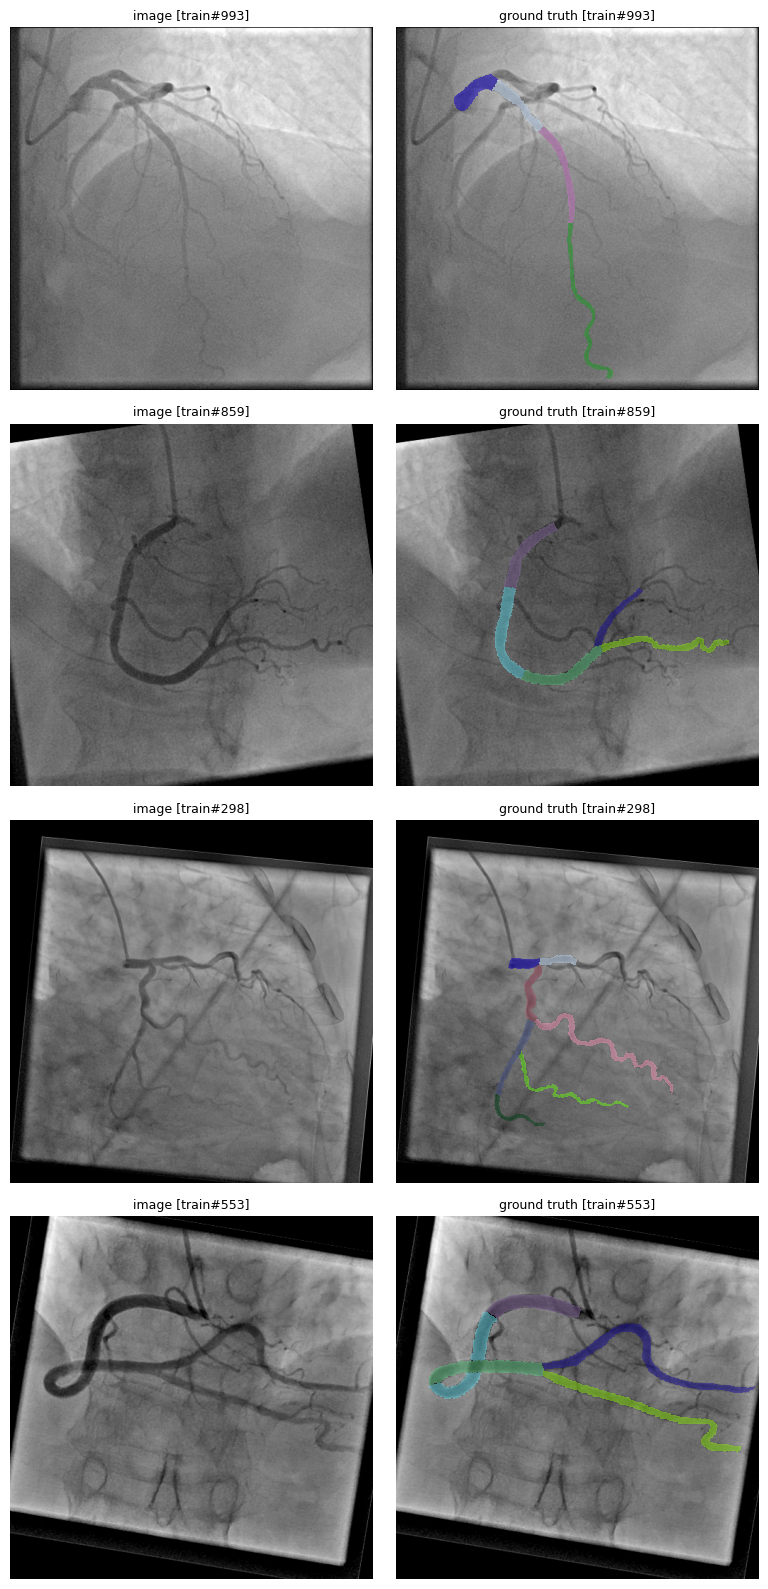

In [ ]:
def denorm(img_t):
    img = img_t.permute(1, 2, 0).cpu().numpy() * IMAGENET_STD + IMAGENET_MEAN
    return np.clip(img, 0, 1)

@torch.no_grad()
def show_sample(ds, n=4, alpha=0.5, seed=None, model=None):
    "Image | ground truth | (optional) model prediction."
    rng = np.random.RandomState(seed)
    idxs = rng.choice(len(ds), size=min(n, len(ds)), replace=False)
    palette = np.random.RandomState(0).rand(len(ds.codes), 3)
    ncols = 3 if model is not None else 2
    fig, axes = plt.subplots(len(idxs), ncols, figsize=(4 * ncols, 4 * len(idxs)), squeeze=False)
    if model is not None: model.eval()

    for r, i in enumerate(idxs):
        img_t, mask_t = ds[int(i)]
        img = denorm(img_t)
        panels = [('image', None), ('ground truth', mask_t.numpy())]
        if model is not None:
            pred = model(img_t[None].to(device)).argmax(1)[0].cpu().numpy()
            panels.append(('prediction', pred))
        for c, (title, m) in enumerate(panels):
            ax = axes[r, c]
            ax.imshow(img)
            if m is not None:
                rgba = np.zeros((*m.shape, 4))
                rgba[..., :3] = palette[m]
                rgba[..., 3] = np.where(m > 0, alpha, 0)
                ax.imshow(rgba, interpolation='nearest')
            ax.set_title(f'{title} [{ds.split}#{i}]', fontsize=9)
            ax.axis('off')
    plt.tight_layout(); plt.show()

show_sample(train_ds, seed=0)

## Model: U-Net with ResNet34 encoder

Encoder = torchvision ResNet34 (ImageNet weights). Decoder = four upsample + skip-connection + 2x(conv-BN-ReLU) blocks.
For a 512x512 input the feature maps are 256 (stem), 128, 64, 32, 16 (layer4).

In [ ]:
def conv_bn_relu(c_in, c_out):
    return nn.Sequential(nn.Conv2d(c_in, c_out, 3, padding=1, bias=False),
                         nn.BatchNorm2d(c_out), nn.ReLU(inplace=True))

class DecoderBlock(nn.Module):
    def __init__(self, c_in, c_skip, c_out):
        super().__init__()
        self.conv1 = conv_bn_relu(c_in + c_skip, c_out)
        self.conv2 = conv_bn_relu(c_out, c_out)
    def forward(self, x, skip):
        x = F.interpolate(x, size=skip.shape[-2:], mode='bilinear', align_corners=False)
        return self.conv2(self.conv1(torch.cat([x, skip], dim=1)))

class UNetResNet34(nn.Module):
    def __init__(self, n_classes, pretrained=True):
        super().__init__()
        b = resnet34(weights=ResNet34_Weights.IMAGENET1K_V1 if pretrained else None)
        self.stem = nn.Sequential(b.conv1, b.bn1, b.relu)       # 64 ch,  1/2
        self.pool = b.maxpool                                    #         1/4
        self.layer1, self.layer2 = b.layer1, b.layer2            # 64 ch 1/4, 128 ch 1/8
        self.layer3, self.layer4 = b.layer3, b.layer4            # 256 ch 1/16, 512 ch 1/32

        self.dec4 = DecoderBlock(512, 256, 256)
        self.dec3 = DecoderBlock(256, 128, 128)
        self.dec2 = DecoderBlock(128,  64,  64)
        self.dec1 = DecoderBlock( 64,  64,  32)
        self.head = nn.Sequential(conv_bn_relu(32, 32), nn.Conv2d(32, n_classes, 1))

    def forward(self, x):
        s0 = self.stem(x)
        s1 = self.layer1(self.pool(s0))
        s2 = self.layer2(s1)
        s3 = self.layer3(s2)
        s4 = self.layer4(s3)
        d = self.dec4(s4, s3)
        d = self.dec3(d, s2)
        d = self.dec2(d, s1)
        d = self.dec1(d, s0)
        d = F.interpolate(d, size=x.shape[-2:], mode='bilinear', align_corners=False)
        return self.head(d)

    def encoder_params(self):
        mods = [self.stem, self.layer1, self.layer2, self.layer3, self.layer4]
        return [p for m in mods for p in m.parameters()]
    def decoder_params(self):
        mods = [self.dec4, self.dec3, self.dec2, self.dec1, self.head]
        return [p for m in mods for p in m.parameters()]

def set_encoder_trainable(model, flag):
    for p in model.encoder_params():
        p.requires_grad = flag

model = UNetResNet34(N_CLASSES).to(device)


x, y = next(iter(train_dl))
with torch.no_grad():
    logits = model(x.to(device))
print('input', tuple(x.shape), '-> logits', tuple(logits.shape), '| mask', tuple(y.shape),
      '| max label', int(y.max()), '(must be <', N_CLASSES, ')')

Downloading: "https://download.pytorch.org/models/resnet34-b627a593.pth" to /root/.cache/torch/hub/checkpoints/resnet34-b627a593.pth


100%|██████████| 83.3M/83.3M [00:00<00:00, 160MB/s]


input (8, 3, 512, 512) -> logits (8, 27, 512, 512) | mask (8, 512, 512) | max label 25 (must be < 27 )


## Loss and metric

* Class weights from train pixel frequencies (ENet-style), so rare artery segments are not ignored.
* Loss = 0.3 x weighted cross-entropy + 0.7 x Dice (Dice ignores background and skips classes absent from the batch).
* Metric = macro-F1 over classes present in the target, excluding background. For pixels, F1 equals Dice.

In [ ]:
def class_weights_from_masks(masks, n_classes, max_w=10.0):
    cnt = torch.zeros(n_classes)
    for m in masks:
        cnt += torch.bincount(torch.from_numpy(m).flatten().long(), minlength=n_classes).float()
    w = 1.0 / torch.log(1.02 + cnt / cnt.sum())
    return (w / w.mean()).clamp(max=max_w)

class DiceLossNoBG(nn.Module):
    def __init__(self, smooth=1.0):
        super().__init__(); self.smooth = smooth
    def forward(self, logits, targ):
        n = logits.shape[1]
        p = F.softmax(logits, dim=1)[:, 1:]
        t = F.one_hot(targ, n).permute(0, 3, 1, 2).float()[:, 1:]
        inter = (p * t).sum((0, 2, 3))
        denom = p.sum((0, 2, 3)) + t.sum((0, 2, 3))
        present = t.sum((0, 2, 3)) > 0
        if not present.any():
            return logits.sum() * 0.0
        dice = (2 * inter + self.smooth) / (denom + self.smooth)
        return 1 - dice[present].mean()

class ComboLoss(nn.Module):
    def __init__(self, class_weights, alpha=0.3):
        super().__init__()
        self.register_buffer('w', class_weights)
        self.dice = DiceLossNoBG()
        self.alpha = alpha
    def forward(self, logits, targ):
        ce = F.cross_entropy(logits, targ, weight=self.w)
        return self.alpha * ce + (1 - self.alpha) * self.dice(logits, targ)

class ConfusionMatrix:
    def __init__(self, n):
        self.n = n; self.reset()
    def reset(self):
        self.cm = torch.zeros(self.n, self.n, dtype=torch.long)    # rows = target, cols = prediction
    @torch.no_grad()
    def update(self, logits, targ):
        pred = logits.argmax(1).flatten().cpu()
        t = targ.flatten().cpu()
        self.cm += torch.bincount(t * self.n + pred, minlength=self.n ** 2).reshape(self.n, self.n)
    def per_class(self):
        tp = self.cm.diag().float()
        fp = self.cm.sum(0).float() - tp
        fn = self.cm.sum(1).float() - tp
        f1 = 2 * tp / (2 * tp + fp + fn).clamp(min=1)
        return f1, tp + fn, tp + fp                                 # f1, target px, predicted px
    def macro_f1(self):
        f1, target_px, _ = self.per_class()
        present = target_px > 0
        present[0] = False                                          # ignore background
        return f1[present].mean().item()

weights = class_weights_from_masks(train_ds.masks, N_CLASSES)
loss_fn = ComboLoss(weights.to(device), alpha=0.3).to(device)
print('class weights:', weights.numpy().round(2))

class weights: [0.03 0.98 0.97 0.98 1.01 0.99 0.95 0.97 0.99 1.01 1.07 1.09 1.1  1.
 1.07 1.03 0.99 1.05 1.08 1.09 1.04 1.09 1.09 1.09 1.07 1.07 1.1 ]


## Training loop

Two phases, like fastai's `fine_tune`: (1) train only the decoder with the encoder frozen, then (2) unfreeze everything and use a lower learning rate for the pretrained encoder.
Each phase uses AdamW + OneCycle LR, mixed precision on GPU, and saves a checkpoint every epoch plus the best one by validation macro-F1.

In [ ]:
history = []
best = {'f1': -1.0}

def run_epoch(model, dl, loss_fn, optimizer=None, scheduler=None, scaler=None, cm=None):
    training = optimizer is not None
    model.train(training)
    total, n = 0.0, 0
    for x, y in dl:
        x = x.to(device, non_blocking=True)
        y = y.to(device, non_blocking=True)
        with torch.set_grad_enabled(training):
            with torch.autocast(device_type='cuda', dtype=torch.float16, enabled=use_amp):
                logits = model(x)
            loss = loss_fn(logits.float(), y)          # loss in fp32 for stability
        if training:
            optimizer.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scaler.step(optimizer); scaler.update()
            scheduler.step()
        else:
            cm.update(logits.float(), y)
        total += loss.item() * x.size(0); n += x.size(0)
    return total / n

def fit(model, epochs, lr_dec, lr_enc=None, phase=''):
    freeze = lr_enc is None
    set_encoder_trainable(model, not freeze)
    groups = [{'params': model.decoder_params(), 'lr': lr_dec}]
    if not freeze:
        groups.insert(0, {'params': model.encoder_params(), 'lr': lr_enc})
    optimizer = torch.optim.AdamW(groups, weight_decay=1e-4)
    scheduler = torch.optim.lr_scheduler.OneCycleLR(
        optimizer, max_lr=[g['lr'] for g in groups], total_steps=epochs * len(train_dl))
    scaler = torch.amp.GradScaler(device, enabled=use_amp)

    for epoch in range(epochs):
        t0 = time.time()
        tr_loss = run_epoch(model, train_dl, loss_fn, optimizer, scheduler, scaler)
        cm = ConfusionMatrix(N_CLASSES)
        va_loss = run_epoch(model, val_dl, loss_fn, cm=cm)
        f1 = cm.macro_f1()
        history.append({'phase': phase, 'train_loss': tr_loss, 'val_loss': va_loss, 'val_f1': f1})

        ckpt = {'model': model.state_dict(), 'codes': train_ds.codes, 'val_f1': f1}
        torch.save(ckpt, CKPT_DIR / 'last.pt')
        if f1 > best['f1']:
            best['f1'] = f1
            torch.save(ckpt, CKPT_DIR / 'best.pt')
        print(f'[{phase}] epoch {epoch+1:>2}/{epochs}  train {tr_loss:.4f}  val {va_loss:.4f}  '
              f'val macro-F1 {f1:.4f}  best {best["f1"]:.4f}  ({time.time()-t0:.0f}s)')

In [ ]:
# Phase 1: decoder only
fit(model, EPOCHS_FROZEN, lr_dec=LR_HEAD, phase='frozen')

In [ ]:
# Phase 2: fine-tune everything
fit(model, EPOCHS_FINETUNE, lr_dec=LR_FT_DEC, lr_enc=LR_FT_ENC, phase='finetune')

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].plot([h['train_loss'] for h in history], label='train')
ax[0].plot([h['val_loss'] for h in history], label='val')
ax[0].set_title('loss'); ax[0].set_xlabel('epoch'); ax[0].legend()
ax[1].plot([h['val_f1'] for h in history])
ax[1].set_title('validation macro-F1'); ax[1].set_xlabel('epoch')
plt.tight_layout(); plt.show()

## Test evaluation (run once, at the end)

Loads the best checkpoint (chosen on validation data) and evaluates on the untouched test split.
Works after a runtime reset as long as `checkpoints/best.pt` still exists and the cells above (imports, dataset, model, metric classes) have been re-run.

In [ ]:
ckpt = torch.load(CKPT_DIR / 'best.pt', map_location=device)
model = UNetResNet34(N_CLASSES, pretrained=False).to(device)
model.load_state_dict(ckpt['model'])
print(f"loaded best checkpoint (val macro-F1 {ckpt['val_f1']:.4f})")

cm = ConfusionMatrix(N_CLASSES)
model.eval()
with torch.no_grad():
    for x, y in test_dl:
        cm.update(model(x.to(device)), y.to(device))

f1, target_px, pred_px = cm.per_class()
print(f"{'class':>8} | {'target px':>10} | {'pred px':>10} | F1")
for i in range(1, N_CLASSES):
    print(f'{train_ds.codes[i]:>8} | {int(target_px[i]):>10} | {int(pred_px[i]):>10} | {f1[i]:.3f}')
print('\nTEST macro-F1 (classes present in test targets):', round(cm.macro_f1(), 4))

loaded best checkpoint (val macro-F1 0.4741)
   class |  target px |    pred px | F1
       1 |     171959 |     218458 | 0.757
       2 |     260366 |     236007 | 0.744
       3 |     165092 |     178711 | 0.784
       4 |     138749 |     111021 | 0.650
       5 |     228953 |     272889 | 0.772
       6 |     242420 |     242951 | 0.673
       7 |     200689 |     222328 | 0.665
       8 |     116081 |     143442 | 0.600
       9 |     157944 |     139316 | 0.320
      9a |      83711 |      82929 | 0.339
      10 |      26528 |      13226 | 0.234
     10a |          0 |          0 | 0.000
      11 |     174061 |     182773 | 0.747
      12 |      33961 |      37247 | 0.166
     12a |      49545 |     119046 | 0.119
      13 |     197759 |     185910 | 0.614
      14 |     161226 |      44222 | 0.211
     14a |      48860 |       4235 | 0.045
      15 |      12052 |      25895 | 0.171
      16 |     113271 |      80622 | 0.671
     16a |      27747 |       9365 | 0.231
     16b |  

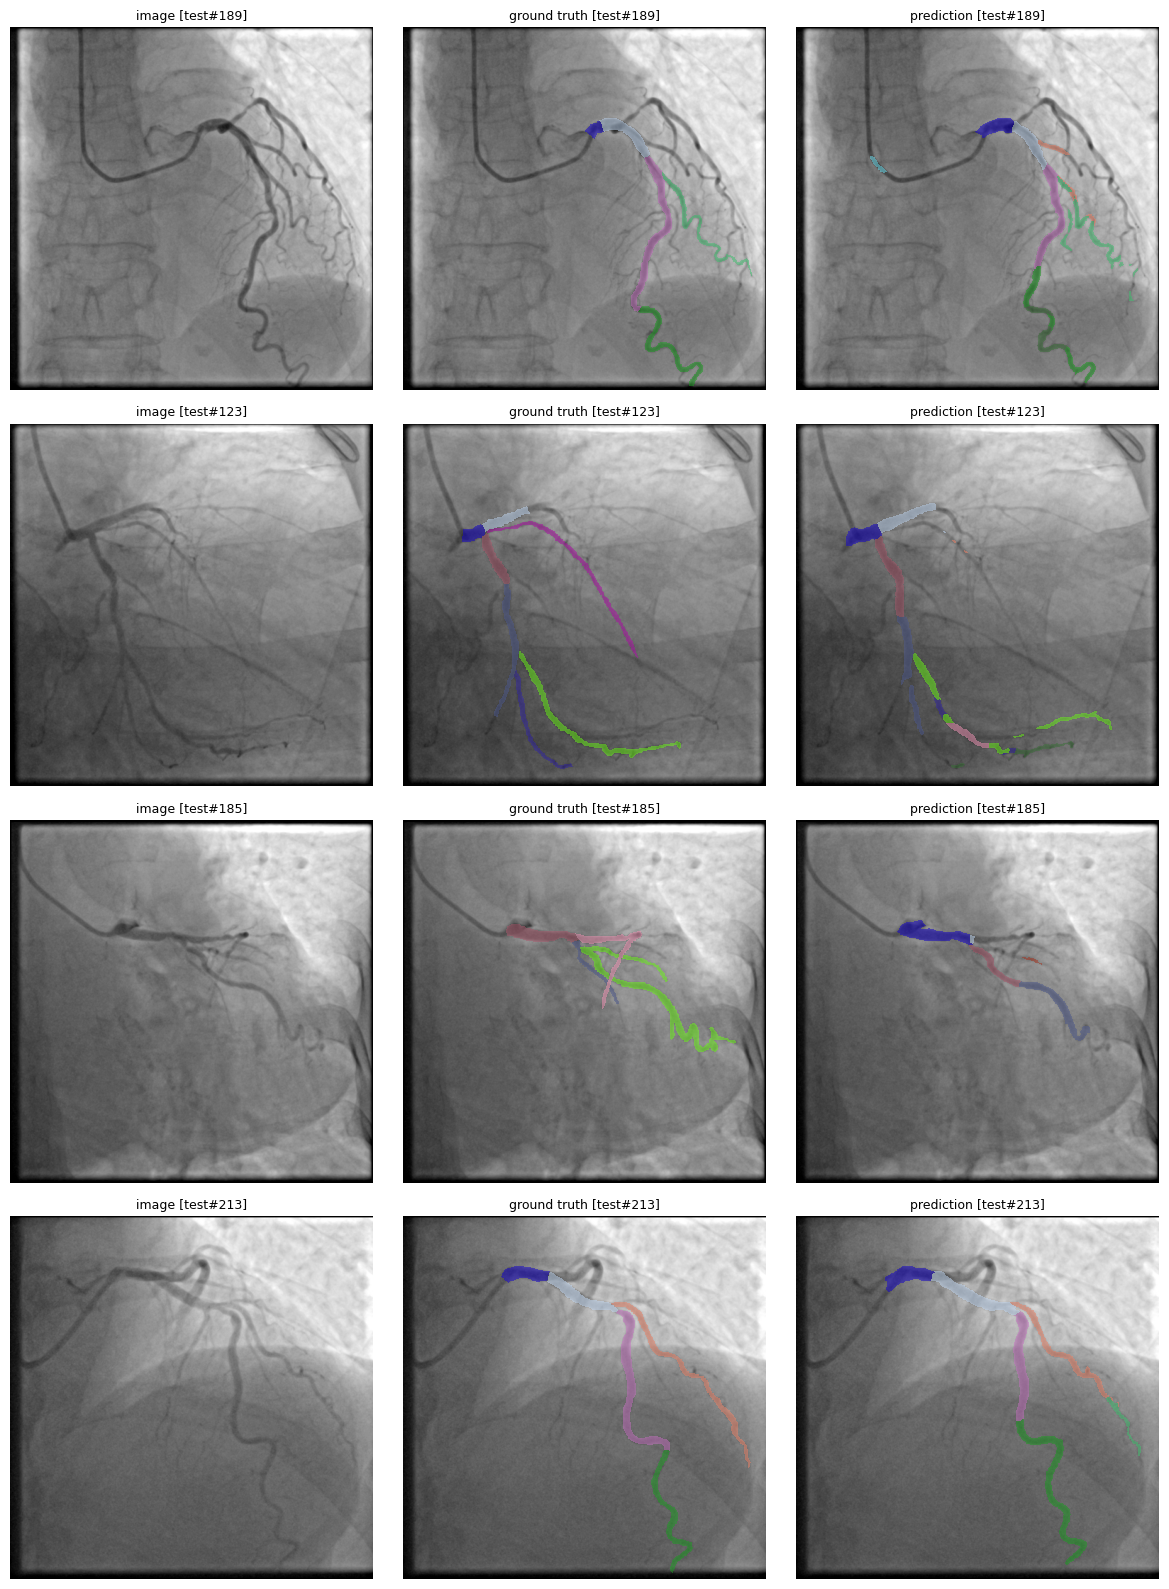

In [ ]:
show_sample(test_ds, n=4, seed=1, model=model)

In [ ]:
codes = train_ds.codes
def top_confusions(cm, name, k=3):
    i = codes.index(name)
    row = cm.cm[i].float(); row = row / row.sum()      # where this class's true pixels were predicted
    vals, idx = row.topk(k + 1)
    print(name, '->', [(codes[j], round(v.item(), 2)) for v, j in zip(vals, idx)])

for n in ['14', '14a', '12a', '9']:
    top_confusions(cm, n)

14 -> [('bg', 0.37), ('12b', 0.21), ('12a', 0.14), ('14', 0.13)]
14a -> [('bg', 0.49), ('14b', 0.11), ('14', 0.09), ('12b', 0.09)]
12a -> [('bg', 0.54), ('12a', 0.2), ('12', 0.11), ('9', 0.09)]
9 -> [('bg', 0.49), ('9', 0.3), ('9a', 0.11), ('12a', 0.04)]


In [ ]:
cm_t = cm.cm.float()
fg_tp = cm_t[1:, 1:].sum()        # vessel pixels predicted as any vessel class
fg_fp = cm_t[0, 1:].sum()         # background predicted as vessel
fg_fn = cm_t[1:, 0].sum()         # vessel predicted as background
print('vessel-vs-background Dice:', (2*fg_tp / (2*fg_tp + fg_fp + fg_fn)).item())
print('correct class among detected vessel pixels:', (cm_t[1:, 1:].diag().sum() / fg_tp).item())

vessel-vs-background Dice: 0.7754319310188293
correct class among detected vessel pixels: 0.7494688034057617


In [ ]:
@torch.no_grad()
def eval_with_bg_bias(model, dl, bias):
    cmx = ConfusionMatrix(N_CLASSES); model.eval()
    for x, y in dl:
        logits = model(x.to(device))
        logits[:, 0] -= bias
        cmx.update(logits, y.to(device))
    return cmx.macro_f1()

for b in [0, 0.5, 1, 1.5, 2, 3]:
    print(b, round(eval_with_bg_bias(model, val_dl, b), 4))

0 0.4742
0.5 0.4733
1 0.4717
1.5 0.4694
2 0.4663
3 0.4579
